In [13]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

In [14]:
with open('victor-hugo-texts.txt', 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip() != '']

print(f"Exemple de texte: {texts[0]}")

Exemple de texte: Mes vers fuiraient


In [41]:
vocab_size = 1000
window_size = 6

tokenizer = Tokenizer(num_words=vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

In [42]:
X = []
y = []
for seq in sequences:
    for i in range(1, len(seq)):
        # prendre au plus les 3 derniers mots avant le mot courant
        start_index = max(0, i - window_size)
        X.append(seq[start_index:i])
        # mot courant
        y.append(seq[i])
X = pad_sequences(X, maxlen=window_size, padding='pre')
y = np.array(y)

print(f"X shape : {X.shape}, y shape : {y.shape}")

X shape : (11541, 6), y shape : (11541,)


In [20]:
embedding_dim = 16
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    SimpleRNN(32),
    Dense(vocab_size, activation='softmax')
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [21]:
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.0355 - loss: 6.1429
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0371 - loss: 5.8163
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0445 - loss: 5.7067
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0482 - loss: 5.6074
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0521 - loss: 5.5256
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0568 - loss: 5.4562
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0626 - loss: 5.3936
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0667 - loss: 5.3343
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0724 - loss: 5.2757
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0782 - loss: 5.2161
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0856 - loss: 5.1542
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

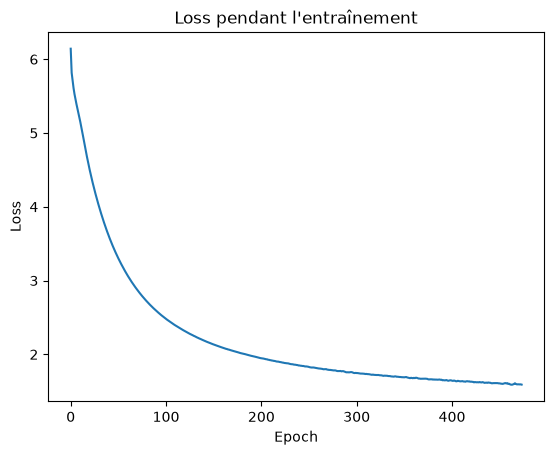

In [22]:
plt.plot(history.history['loss'])
plt.title('Loss pendant l\'entraînement')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [37]:
def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')

        probs = model.predict(tokens, verbose=0)[0]

        probs = np.exp(np.log(probs + 0.000000001) / temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word = tokenizer.index_word.get(index)
        if word is not None:
            text += ' ' + word

    return text


In [33]:
random_text = generate_text("Poème", num_words=50)
print(random_text)

Poème toi en près d'elle rendra plafond faux plein de tous un son de lumière et j'ai jusqu'au son amour que mes fleurs notre heure à sa est vert du allons bois où des morts elle roland sans fait à frères rêves l'oeil profonde singe une nuit « fatal ans et


In [43]:
from tensorflow.keras.layers import LSTM

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    LSTM(64),
    Dense(vocab_size, activation='softmax')
])

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [44]:
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

history = model.fit(
    X, y,
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.0354 - loss: 6.1147
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0351 - loss: 5.8322
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0374 - loss: 5.7681
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0386 - loss: 5.7241
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0418 - loss: 5.6822
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0488 - loss: 5.6299
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0534 - loss: 5.5723
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.0547 - loss: 5.5165
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0572 - loss: 5.4603
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0605 - loss: 5.4027
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.0663 - loss: 5.3409
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

In [47]:
random_text = generate_text("Tu", num_words=15)
print(random_text)

Tu et l'on faut où ton blanc c'est sur les rond sa pieds et là les


Q1 : Le tokenizer indexe chaque mot, l'index entier étant alors la valeur qui est traitée par le modèle qui ne gère que des valeurs numériques.

Q2 : pad_sequences complète un vecteur par des 0 à gauche pour avoir un vecteur avec toujours la même dimension. Il faut toujours 3 mots pour prédire le suivant, donc lorsqu'on commence une phrase, le premier mot est complété par deux 0 pour pouvoir s'en servir pour l'apprentissage ou la prédiction avec le deuxième mot.

Q3 : vocab_size est le nombre global de mots dans le vocabulaire, le réseau établit une probabilité pour chaque mot de ce vocabulaire. Le paramètre embedding_dim correspond à la dimension du vecteur de valeurs utilisées pour représenter chaque mot.

Q4 : Pour les traitements on ne reste pas sur un seul entier indexant le mot, mais un vecteur de réels, transformation faite par la couche Embedding. L'intérêt essentiel est de donner au réseau une représentation plus riche des mots et surtout une représentation qu'il peut apprendre et ajuster. Au cours de l'entraînement, le réseau modifie ces valeurs en fonction des contextes dans lesquels apparaissent les mots. Des mots utilisés dans des contextes similaires peuvent ainsi finir par avoir des représentations proches.

Q5 : SimpleRNN traite séquentiellement les vecteurs issus de l'Embedding en transmettant à chaque étape un état contenant les informations retenues des mots précédents. Le LSTM reprend ce principe de récurrence mais lui ajoute une mémoire et des portes permettant d'apprendre quelles informations doivent être conservées, oubliées ou ajoutées. Il est ainsi mieux adapté à la prise en compte de dépendances à plus long terme dans une séquence.

Q6 : window_size = 3 correspond au nombre de mots utilisés pour prédire le mot suivant, autrement dit la profondeur de la correspondance entre les mots qui se suivent. Plus ce nombre est grand, plus on a une chance d'avoir une phrase cohérente, mais nécessite un entraînement plus important car la combinatoire des mots dans cette fenêtre est plus importante.

Q7 : sparse_categorical_crossentropy mesure l'erreur d'une classification multiclasse lorsque la classe attendue est représentée par son indice entier. Elle pénalise le modèle en fonction de la probabilité qu'il a attribuée à la bonne classe : Loss = -ln(Pbonne classe).

Q8 : EarlyStopping regarde à chaque epoch la loss calculée sur les données de validation. Si elle cesse de diminuer, avec une tolérance (paramètre patience), elle arrête le processus d'entraînement pour éviter le surapprentissage.

Q9 : La convergence de l'apprentissage du modèle se voit lorsque la loss se stabilise au fil des epochs, autrement dit lorsque la dérivée de la courbe de perte (toujours négative) est proche de 0.

Q10 : N'est pas Victor Hugo qui veut ! Plus sérieusement l'entraînement nécessaire à inculquer la grammaire au modèle n'est pas une mince affaire, sans parler du nombre de contextes qu'il doit maîtriser pour employer les mots adéquats. Il faudrait aussi un objet aux phrases à construire. En attendant, les phrases construites ne respectent pas la grammaire et ne veulent rien dire.